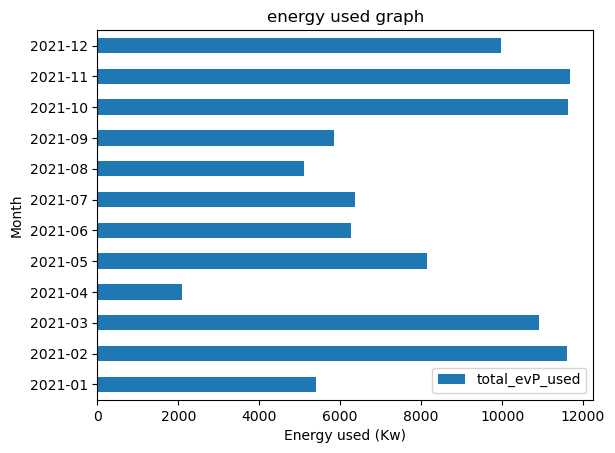

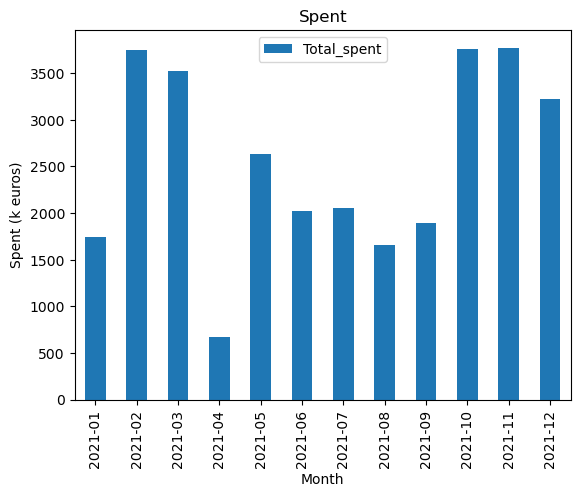

TypeError: 'DataFrame' object is not callable

In [5]:
# new line

import pandas as pd

import matplotlib.pyplot as plt



research_collect = pd.read_csv("discovergyTesla1min.csv")


#gathering total power used across 3 phases
total_ev =  research_collect['evP1'] + research_collect['evP2'] + research_collect["evP3"]

total_mains = research_collect["mainsP1"] + research_collect["mainsP2"] + research_collect["mainsP2"]

#putting these gathered powers into the data frame in their own columns
overall_use = research_collect.assign(total_evP_used = total_ev,total_mains_used = total_mains)

#making the timestamps actual timestamps
overall_use['timestamps'] = pd.to_datetime(overall_use['timestamps'])


#grouping data into hours 
hours = overall_use.groupby(pd.PeriodIndex(overall_use['timestamps'], freq='h'))[['total_evP_used',"total_mains_used"]].sum()
#grouping data by days
days = overall_use.groupby(pd.PeriodIndex(overall_use['timestamps'], freq='D'))[['total_evP_used',"total_mains_used"]].sum()
#grouping data by months
months = overall_use.groupby(pd.PeriodIndex(overall_use['timestamps'], freq = 'M'))[['total_evP_used','total_mains_used']].sum()





#using kwh rate in germany to find total energy spent
Multiplying_by_hourly_rate = hours.assign(Total_spent=hours['total_evP_used']*0.3234)

#grouping data frame

temp = pd.PeriodIndex(Multiplying_by_hourly_rate.index, freq = 'M')
Monthly_spent = Multiplying_by_hourly_rate.groupby(temp)[['Total_spent','total_evP_used','total_mains_used']].sum()

#standard deviations
sd_h = hours.std()

sd_d = days.std()

sd_m = months.std()

#energy used graph

(months['total_evP_used']/1000).plot(kind = 'barh')
plt.title('energy used graph')
plt.legend()
plt.xlabel('Energy used (Kw)')
plt.ylabel('Month')
plt.show()


#spendage graph
(Monthly_spent['Total_spent']/1000).plot(kind = 'bar')

plt.title('Spent')
plt.legend()
plt.ylabel('Spent (k euros)')
plt.xlabel('Month')
plt.show()








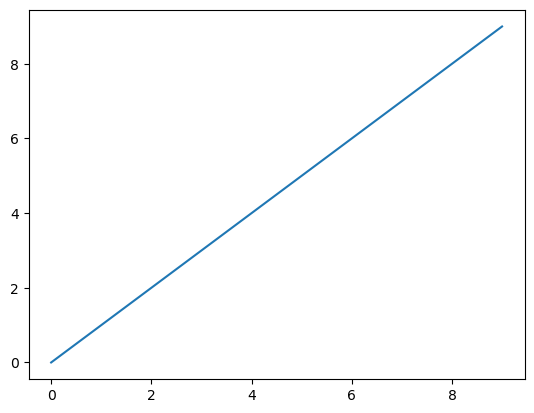

In [3]:
#way to check where something has went wrong
plt.figure()
plt.plot(range(0, 10), range(0, 10))
plt.show()

statistical anlysis

The maximum value of the total power used is 615258.8515000001 and it occurred at 2021-11-14 15:00.
the highest point mains was at was 676647.7613333333 at 2021-05-30 15:00


<Axes: >

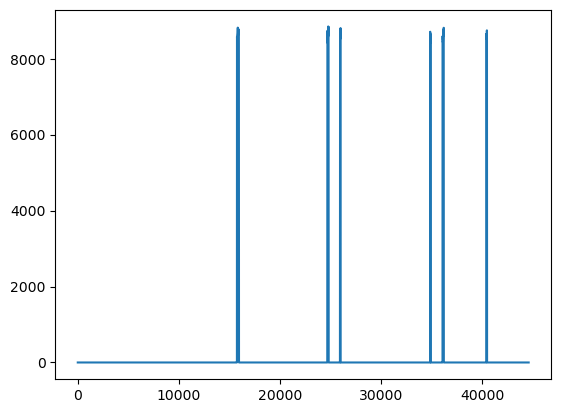

In [28]:
#getting max and min
# Find the maximum value of variable
max_value = hours['total_evP_used'].max()
max_value2 = hours['total_mains_used'].max()

# Find the time at which the maximum value occurred
max_time = hours.loc[hours['total_evP_used'].idxmax()] # ['2020-01-01':'2020-01-02'] iloc[0:10]
max_time2 = hours.loc[hours['total_mains_used'].idxmax()]

# Display the results 
print(f'The maximum value of the total power used is {max_value} and it occurred at {max_time.name}.')
print(f'the highest point mains was at was {max_value2} at {max_time2.name}')

#creating a graph showing when values go above 0
above_35 = hours[hours['total_evP_used']>0]

rev = overall_use['total_evP_used'].iloc[1:44579]
rev.plot()


event detection

In [ ]:
days_with_energy_used = days[days['total_evP_used'] > 0]

mean_days_per_month_with_energy_used = days_with_energy_used.resample('M').size().mean()
print(mean_days_per_month_with_energy_used)

8.25


In [ ]:
print(monthly_usage.index)

NameError: name 'monthly_usage' is not defined

In [ ]:
import csv

# Open a CSV file for writing ('w' mode)
with open('persons.csv', 'w', newline='') as csvfile:
    filewriter = csv.writer(csvfile, delimiter=',', quotechar='|', quoting=csv.QUOTE_MINIMAL)

    # Write header row
    filewriter.writerow(['timestamp','Name', 'Profession'])

    # Write data rows
    filewriter.writerow([0,'Derek', 'Software Developer'])
    filewriter.writerow([1,'Steve', 'Software Developer'])
    filewriter.writerow([2,'Paul', 'Manager'])
    filewriter.writerow([0,'Derek', 'Software Developer'])
    filewriter.writerow([1,'Steve', 'Software Developer'])
    filewriter.writerow([2,'Paul', 'Manager'])
    filewriter.writerow([0,'Derek', 'Software Developer'])
    filewriter.writerow([1,'Steve', 'Software Developer'])
    filewriter.writerow([2,'Paul', 'Manager'])
    filewriter.writerow([0,'Derek', 'Software Developer'])
    filewriter.writerow([1,'Steve', 'Software Developer'])
    filewriter.writerow([2,'Paul', 'Manager'])

r = pd.read_csv('persons.csv')
print(r['timestamp'])


GUI

In [52]:
def Dataframe():
    global overall_use
    research_collect = pd.read_csv("discovergyTesla1min.csv")


    #gathering total power used across 3 phases
    total_ev =  research_collect['evP1'] + research_collect['evP2'] + research_collect["evP3"]

    total_mains = research_collect["mainsP1"] + research_collect["mainsP2"] + research_collect["mainsP2"]

    #putting these gathered powers into the data frame in their own columns
    overall_use = research_collect.assign(total_evP_used = total_ev,total_mains_used = total_mains)
    #making the timestamps actual timestamps
    overall_use['timestamps'] = pd.to_datetime(overall_use['timestamps'])

def patterns_useful():
    #grouping data into hours 
    hours = overall_use.groupby(pd.PeriodIndex(overall_use['timestamps'], freq='h'))[['total_evP_used',"total_mains_used"]].sum()
    #grouping data by days
    days = overall_use.groupby(pd.PeriodIndex(overall_use['timestamps'], freq='D'))[['total_evP_used',"total_mains_used"]].sum()
    #grouping data by months
    months = overall_use.groupby(pd.PeriodIndex(overall_use['timestamps'], freq = 'M'))[['total_evP_used','total_mains_used']].sum()





    #using kwh rate in germany to find total energy spent
    Multiplying_by_hourly_rate = hours.assign(Total_spent=hours['total_evP_used']*0.3234)

    #grouping data frame

    temp = pd.PeriodIndex(Multiplying_by_hourly_rate.index, freq = 'M')
    Monthly_spent = Multiplying_by_hourly_rate.groupby(temp)[['Total_spent','total_evP_used','total_mains_used']].sum()

    #standard deviations
    sd_h = hours.std()

    sd_d = days.std()

    sd_m = months.std()

    #energy used graph

    (months['total_evP_used']/1000).plot(kind = 'barh')
    plt.title('energy used graph')
    plt.legend()
    plt.xlabel('Energy used (Kw)')
    plt.ylabel('Month')
    plt.show()


    #spendage graph
    (Monthly_spent['Total_spent']/1000).plot(kind = 'bar')

    plt.title('Spent')
    plt.legend()
    plt.ylabel('Spent (k euros)')
    plt.xlabel('Month')
    plt.show()

def pat():
    print('p')

def ev_det():
    print('works')

def stats():
    print('stats')

#possibly need to change this

play = True
ip = input('hi there are you looking for information on phase shifting? y/n')
if ip == 'y':
    print('great')

    while play:
        
            finished = False
            while not finished:
                print('1.event detection')
                print('2.statistical analysis')
                print('3.Paterns and useful features')
                ip2 = str(input('what type of data? please decide from the choices shown above'))
                if ip2 == 'event detection' or ip2 == 'Event detection':
                    print('event')
                    
                    finished = True
                elif ip2 =='statistical analysis' or ip2 == 'Statistical analysis':
                    stats()
                    finished = True
                elif ip2 == 'patterns and useful features' or ip2 == 'Patterns and useful features':
                    pat()
                    finished = True

                else:
                    print('yuck')
                    finished = False
            ip3 = input('anything else?')
            if ip3 == 'n':
                print('thanks')
                play = False
            if ip3 == 'y':
                print('reloading')

else:
    print('nani!?')





great
1.event detection
2.statistical analysis
3.Paterns and useful features
event
thanks
